# **Planteamiento del problema**

---

#### **Contexto de negocio**
La Última Milla (*Last Mile Delivery*) es la etapa final y más costosa de la cadena logística: llevar un paquete desde la estación local hasta la puerta del cliente. Suele representar la mayor parte del costo total de envío y es la etapa que más impacta en la experiencia del cliente, ya que define si se cumple o no la promesa de entrega.

Este proyecto se enfoca en las operaciones de Última Milla en **Shanghái**, uno de los centros comerciales más densos y complejos del mundo. Allí, los tiempos de entrega se ven afectados por factores geográficos (zona, distancia, tipo de área) y temporales (hora del día, día de la semana, horas pico). Poder anticipar cuánto va a demorar una entrega le permite a la empresa fijar promesas de entrega realistas, planificar la capacidad de la flota e identificar zonas y franjas horarias críticas.

Los datos provienen de **LaDe (Last-mile Delivery dataset)**, publicado por Cainiao, el brazo logístico de Alibaba. Abarcan **6 meses de operaciones**, con **1.483.864 pedidos** y **17 columnas**, realizados por **1.733 couriers** en **52 regiones** de la ciudad. El dataset no tiene valores nulos ni pedidos duplicados, y las coordenadas GPS están anonimizadas con un radio de aproximación de unos 10 metros.

---

#### **Objetivo**
El objetivo es construir un **modelo de regresión supervisado** que prediga el **tiempo de entrega en minutos** (`tiempo_entrega_min`) de cada pedido, medido desde que el courier acepta la tarea (`accept_time`) hasta que entrega el paquete (`delivery_time`).

Con este modelo, la empresa busca:
1. Dar a los clientes estimaciones de tiempo de entrega más precisas.
2. Entender qué factores geográficos y temporales tienen mayor impacto en los tiempos de entrega.
3. Apoyar decisiones operativas como la asignación de couriers, la planificación de la carga de trabajo por franja horaria y el foco en zonas críticas.

Para lograrlo, limpiamos los datos, creamos nuevas variables (distancia, velocidad, experiencia del courier, hora del día, día de la semana), exploramos su relación con el target, y entrenamos y evaluamos modelos de regresión con RMSE, MAE, R² y R² ajustado.

---

#### **Diccionario de datos**
Cada fila del dataset representa un pedido de entrega. Los atributos originales son:

1. **Información del pedido**
   - **order_id:** Identificador único de cada paquete.
   - **ds:** Fecha del pedido (formato MMDD).

2. **Información de ubicación**
   - **city:** Ciudad donde se realiza la entrega (Shanghái).
   - **region_id:** Identificador de la región.
   - **aoi_id:** Identificador del Área de Interés (AOI) donde se entrega el paquete.
   - **aoi_type:** Tipo de AOI (código categórico, por ejemplo residencial, comercial, escuela).
   - **lng / lat:** Coordenadas del lugar de entrega del paquete.

3. **Información del courier**
   - **courier_id:** Identificador único del courier.

4. **Eventos de la tarea**
   - **accept_time:** Fecha y hora en que el courier acepta la tarea (formato MM-DD HH:MM:SS).
   - **accept_gps_time:** Fecha y hora del punto GPS más cercano al momento de aceptación.
   - **accept_gps_lng / accept_gps_lat:** Coordenadas del courier al aceptar la tarea.
   - **delivery_time:** Fecha y hora en que el courier completa la entrega (formato MM-DD HH:MM:SS).
   - **delivery_gps_time:** Fecha y hora del punto GPS más cercano al momento de entrega.
   - **delivery_gps_lng / delivery_gps_lat:** Coordenadas del courier al completar la entrega.

5. **Variable target (creada)**
   - **tiempo_entrega_min:** Tiempo de entrega en minutos, calculado como `delivery_time - accept_time`.

## **Importación de librerías**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder

# Modelos
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Para evaluar el desempeño de los modelos
from sklearn.metrics import make_scorer,mean_squared_error, r2_score, mean_absolute_error

# Para ignorar warnings innecesarios (por ejemplo, los RuntimeWarning de numpy en el cálculo matricial)
import warnings
warnings.filterwarnings("ignore")

## **Carga de datos**

In [2]:
# Importación de los datos
def get_my_data():
    url = "https://huggingface.co/datasets/Cainiao-AI/LaDe/resolve/main/delivery/delivery_sh.csv"
    df = pd.read_csv(url)
    return df
df = get_my_data()

In [3]:
# Ver las primeras 5 filas del dataset
df.head()

,order_id,region_id,city,courier_id,lng,lat,aoi_id,aoi_type,accept_time,accept_gps_time,accept_gps_lng,accept_gps_lat,delivery_time,delivery_gps_time,delivery_gps_lng,delivery_gps_lat,ds
0,3158819,1,Shanghai,164,121.52128,31.06614,450,1,06-04 11:05:00,06-04 11:05:00,121.52281,31.10598,06-04 17:40:00,06-04 17:40:00,121.52407,31.06614,604
1,751342,1,Shanghai,164,121.52124,31.06687,450,1,06-04 11:18:00,06-04 11:18:00,121.52286,31.10599,06-04 15:06:00,06-04 15:06:00,121.52412,31.06618,604
2,3380476,1,Shanghai,164,121.52106,31.06731,450,1,06-03 10:13:00,06-03 10:13:00,121.52285,31.10591,06-03 15:11:00,06-03 15:11:00,121.52059,31.06672,603
3,2184571,1,Shanghai,164,121.52128,31.06616,450,1,06-04 10:39:00,06-04 10:39:00,121.52282,31.10593,06-04 15:41:00,06-04 15:41:00,121.52280,31.10542,604
4,941371,1,Shanghai,164,121.52123,31.06614,450,1,06-04 11:18:00,06-04 11:18:00,121.52285,31.10593,06-04 14:07:00,06-04 14:07:00,121.52290,31.06758,604


## **Data Overview**

#### **Tipos de datos**

In [4]:
# Dimensiones del dataset
print(f"El dataset tiene {df.shape[0]} filas y {df.shape[1]} columnas.\n")

# Nombres de columnas, cantidad de valores no nulos y tipos de datos
df.info()

El dataset tiene 1483864 filas y 17 columnas.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1483864 entries, 0 to 1483863
Data columns (total 17 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   order_id           1483864 non-null  int64  
 1   region_id          1483864 non-null  int64  
 2   city               1483864 non-null  object 
 3   courier_id         1483864 non-null  int64  
 4   lng                1483864 non-null  float64
 5   lat                1483864 non-null  float64
 6   aoi_id             1483864 non-null  int64  
 7   aoi_type           1483864 non-null  int64  
 8   accept_time        1483864 non-null  object 
 9   accept_gps_time    1483864 non-null  object 
 10  accept_gps_lng     1483864 non-null  float64
 11  accept_gps_lat     1483864 non-null  float64
 12  delivery_time      1483864 non-null  object 
 13  delivery_gps_time  1483864 non-null  object 
 14  delivery_gps_lng   1483864 non-null

In [5]:
# Cantidad de valores únicos por columna (ordenados de mayor a menor)
resumen_unicos = pd.DataFrame({
    'columna': df.columns,
    'valores_unicos': [df[col].nunique() for col in df.columns]
})

resumen_unicos.sort_values(by='valores_unicos', ascending=False).reset_index(drop=True)

,columna,valores_unicos
0,order_id,1483864
1,delivery_gps_time,144334
2,delivery_time,144334
3,accept_gps_time,130836
4,accept_time,130836
5,delivery_gps_lng,73503
6,lng,68747
7,delivery_gps_lat,58280
8,lat,56161
9,aoi_id,15564


##### **Observaciones:**
<small><font color="gray">Tipos de datos</font></small>

- El dataset tiene 1.483.864 filas y 17 columnas. Cada fila es un pedido de entrega.
- 6 columnas son int64, 6 son float64 y 5 son texto (object).
- `order_id`, `region_id`, `courier_id`, `aoi_id` y `aoi_type` están guardadas como enteros, pero son identificadores o códigos de categoría, no cantidades.
- `order_id` tiene un valor único por fila, así que identifica a cada pedido.
- `city` tiene un único valor (Shanghai), por lo que no aporta información al modelo.
- Hay 52 regiones, 16 tipos de AOI, 15.564 AOIs y 1.733 couriers.
- `ds` tiene 184 valores únicos, lo que confirma que los datos abarcan unos 6 meses de operaciones.
- Las coordenadas de entrega (`lng`, `lat`, `delivery_gps_*`) tienen entre 56.000 y 74.000 valores únicos, mientras que las de aceptación (`accept_gps_*`) tienen solo unos 1.250. Esto indica que los couriers aceptan sus pedidos desde un número reducido de puntos fijos (estaciones o depósitos).
- Las columnas de tiempo (`accept_time`, `accept_gps_time`, `delivery_time`, `delivery_gps_time`) están guardadas como texto con formato MM-DD HH:MM:SS, sin el año. Hay que convertirlas a datetime para calcular el tiempo de entrega.

#### **Resumen estadístico**

In [6]:
# Resumen estadístico de las columnas numéricas (transpuesto para facilitar la lectura)
df.describe().T

,count,mean,std,min,25%,50%,75%,max
order_id,1483864.0,2.256844e+06,1.303169e+06,2.00000,1.128599e+06,2.256111e+06,3.385764e+06,4.514655e+06
region_id,1483864.0,4.575173e+01,2.716011e+01,1.00000,2.200000e+01,4.500000e+01,6.900000e+01,1.600000e+02
courier_id,1483864.0,2.430808e+03,1.373688e+03,0.00000,1.314000e+03,2.411000e+03,3.617000e+03,4.874000e+03
lng,1483864.0,1.214720e+02,1.413028e-01,102.08492,1.213992e+02,1.214838e+02,1.215417e+02,1.219547e+02
lat,1483864.0,3.119236e+01,1.084289e-01,26.69903,3.114591e+01,3.120879e+01,3.125087e+01,3.991190e+01
aoi_id,1483864.0,3.024220e+04,1.728783e+04,1.00000,1.521800e+04,3.024800e+04,4.503900e+04,6.014700e+04
aoi_type,1483864.0,3.379326e+00,4.905149e+00,0.00000,1.000000e+00,1.000000e+00,1.000000e+00,1.500000e+01
accept_gps_lng,1483864.0,1.214724e+02,1.314692e-01,106.50668,1.214001e+02,1.214739e+02,1.215308e+02,1.218647e+02
accept_gps_lat,1483864.0,3.119154e+01,1.037831e-01,29.58773,3.113889e+01,3.120761e+01,3.125623e+01,3.141069e+01
delivery_gps_lng,1483864.0,1.214640e+02,9.402852e-01,-0.00009,1.213991e+02,1.214835e+02,1.215423e+02,1.219749e+02


##### **Observaciones:**
<small><font color="gray">Resumen estadístico</font></small>

- Las estadísticas de `order_id`, `region_id`, `courier_id` y `aoi_id` no tienen significado, ya que son identificadores.
- `aoi_type` va de 0 a 15, con una mediana de 1. La mayoría de los pedidos se entregan en el mismo tipo de área.
- `ds` va de 501 a 1031, lo que confirma que los datos abarcan 6 meses de operaciones (mayo a octubre).
- El 50% de las coordenadas está entre longitud 121,40–121,54 y latitud 31,15–31,25, lo que coincide con Shanghái.
- Sin embargo, algunas coordenadas están muy lejos de la ciudad: `lng` tiene un mínimo de 102,08 y `lat` un máximo de 39,91.
- `delivery_gps_lng` y `delivery_gps_lat` tienen un mínimo cercano a 0, lo que indica que algunos puntos GPS no se registraron correctamente. Tratamos estas coordenadas inválidas en la etapa de limpieza de datos.

#### **Valores faltantes**

In [7]:
# Cantidad de valores faltantes por columna
df.isnull().sum()

order_id             0
region_id            0
city                 0
courier_id           0
lng                  0
lat                  0
aoi_id               0
aoi_type             0
accept_time          0
accept_gps_time      0
accept_gps_lng       0
accept_gps_lat       0
delivery_time        0
delivery_gps_time    0
delivery_gps_lng     0
delivery_gps_lat     0
ds                   0
dtype: int64

##### **Observaciones:**
<small><font color="gray">Valores faltantes</font></small>

- No hay valores faltantes en ninguna de las 17 columnas, así que no hace falta imputar.
- Aun así, algunas columnas tienen valores inválidos (como coordenadas GPS iguales a 0), que tratamos más adelante en la etapa de limpieza de datos.

#### **Duplicados y columnas constantes**

In [8]:
# Filas duplicadas exactas (todas las columnas)
print(f"Filas duplicadas exactas: {df.duplicated().sum()}")

# IDs de pedido duplicados
print(f"IDs de pedido duplicados: {df['order_id'].duplicated().sum()}")

# Columnas duplicadas: las columnas de tiempo GPS parecen idénticas a las columnas de tiempo del evento
print(f"accept_time igual a accept_gps_time: {df['accept_time'].equals(df['accept_gps_time'])}")
print(f"delivery_time igual a delivery_gps_time: {df['delivery_time'].equals(df['delivery_gps_time'])}")

Filas duplicadas exactas: 0
IDs de pedido duplicados: 0
accept_time igual a accept_gps_time: True
delivery_time igual a delivery_gps_time: True


In [9]:
# Eliminamos las columnas duplicadas y la columna constante (city tiene un único valor)
# Verificamos que las columnas existan, para evitar un error si la celda se ejecuta dos veces
columns_to_drop = ['accept_gps_time', 'delivery_gps_time', 'city']

existing_columns = [col for col in columns_to_drop if col in df.columns]

if existing_columns:
    df.drop(columns=existing_columns, inplace=True)
    print(f"Columnas eliminadas: {existing_columns}")
else:
    print("Las columnas ya no están en el dataset")

print(f"\nDimensiones después de eliminar columnas: {df.shape}")

Columnas eliminadas: ['accept_gps_time', 'delivery_gps_time', 'city']

Dimensiones después de eliminar columnas: (1483864, 14)


##### **Observaciones:**
<small><font color="gray">Duplicados y columnas constantes</font></small>

- No hay filas duplicadas y cada `order_id` es único, así que cada fila es un pedido distinto.
- Sin embargo, `accept_gps_time` es idéntica a `accept_time`, y `delivery_gps_time` es idéntica a `delivery_time`.
- Eliminamos `accept_gps_time` y `delivery_gps_time` por ser redundantes, y `city` porque tiene un único valor.
- El dataset queda con 1.483.864 filas y 14 columnas.

## **Feature Engineering**

Creamos las nuevas variables antes de la limpieza de datos y del EDA, porque:
- La variable target (`tiempo_entrega_min`) no está en el dataset original, así que primero hay que calcularla.
- Los filtros de limpieza usan algunas de las nuevas variables (tiempo de entrega, distancia y velocidad).
- Queremos analizar las nuevas variables en el EDA, para entender su relación con el tiempo de entrega.

#### **Variable target: tiempo_entrega_min**

In [10]:
# Convertimos las columnas de tiempo a datetime
# El dataset no incluye el año, así que lo agregamos (2022, según la metadata del dataset)
df['accept_time'] = pd.to_datetime('2022-' + df['accept_time'], format='%Y-%m-%d %H:%M:%S')
df['delivery_time'] = pd.to_datetime('2022-' + df['delivery_time'], format='%Y-%m-%d %H:%M:%S')

# Variable target: tiempo de entrega en minutos, desde la aceptación hasta la entrega
df['tiempo_entrega_min'] = (df['delivery_time'] - df['accept_time']).dt.total_seconds() / 60

In [11]:
# Rango de fechas de entrega
min_delivery = df['delivery_time'].min()
max_delivery = df['delivery_time'].max()
print(f"Las fechas de entrega van del {min_delivery} al {max_delivery}")

Las fechas de entrega van del 2022-05-01 08:33:00 al 2022-11-16 23:09:00


In [12]:
# Resumen estadístico de la variable target
print(df['tiempo_entrega_min'].describe())

count    1.483864e+06
mean     1.111406e+02
std      2.191312e+02
min      0.000000e+00
25%      4.300000e+01
50%      7.200000e+01
75%      1.190000e+02
max      4.773900e+04
Name: tiempo_entrega_min, dtype: float64


##### **Observaciones:**
<small><font color="gray">Variable target</font></small>

- Las fechas de entrega van del 2022-05-01 al 2022-11-16.
- La mediana del tiempo de entrega es 72 minutos, y el 50% de los pedidos se entrega entre 43 y 119 minutos.
- La media (111 minutos) es mucho mayor que la mediana y el desvío estándar es muy alto (219 minutos), así que el target tiene una fuerte asimetría a la derecha.
- El mínimo es 0 minutos y el máximo 47.739 minutos (unos 33 días). Estos valores no son razonables para una entrega de última milla, y los tratamos en la etapa de limpieza de datos.

#### **Distancia y velocidad: distancia_km, velocidad_kmh**

In [13]:
# Distancia de Haversine: distancia en línea recta entre dos puntos sobre la superficie de la Tierra
def haversine(lat1, lng1, lat2, lng2):
    R = 6371  # Radio de la Tierra en km
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    dlat, dlng = lat2 - lat1, lng2 - lng1
    a = np.sin(dlat/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin(dlng/2)**2
    return 2 * R * np.arcsin(np.sqrt(a))

# Distancia entre la posición del courier al aceptar la tarea y al entregar el paquete
df['distancia_km'] = haversine(
    df['accept_gps_lat'], df['accept_gps_lng'],
    df['delivery_gps_lat'], df['delivery_gps_lng']
)

# Velocidad promedio implícita de la entrega
df['velocidad_kmh'] = df['distancia_km'] / (df['tiempo_entrega_min'] / 60)

##### **Observaciones:**
<small><font color="gray">Distancia y velocidad</font></small>

- `distancia_km` es la distancia en línea recta entre la posición del courier al aceptar la tarea y al entregar el paquete. La ruta real es más larga, pero esta distancia es una buena aproximación de cuánto tiene que recorrer el courier.
- `velocidad_kmh` es la velocidad promedio implícita de la entrega. La usamos solo para detectar registros inconsistentes en la limpieza de datos y en el EDA.
- `velocidad_kmh` se calcula con el target, así que no la usamos como feature del modelo (generaría data leakage).

#### **Experiencia del courier: experiencia_courier**

In [14]:
# Experiencia del courier: cantidad de pedidos que el courier ya había aceptado ANTES del pedido actual
# Solo usa pedidos pasados del mismo courier, para evitar data leakage temporal

# Ordenamos por courier y hora de aceptación
df = df.sort_values(['courier_id', 'accept_time'])

# Conteo acumulado de pedidos previos del courier (sin contar el pedido actual)
df['experiencia_courier'] = df.groupby('courier_id').cumcount()

##### **Observaciones:**
<small><font color="gray">Experiencia del courier</font></small>

- `courier_id` tiene 1.733 valores, así que no se puede usar directamente en el modelo. En su lugar, usamos `experiencia_courier` para capturar la experiencia del courier.
- El primer pedido de cada courier tiene experiencia 0, y el valor aumenta con cada pedido nuevo.
- Solo usa información disponible al momento del pedido, así que no genera data leakage.

#### **Variables temporales: hora_dia, dia_semana, es_finde**

In [15]:
# Variables temporales extraídas de la hora de aceptación
df['hora_dia'] = df['accept_time'].dt.hour                    # hora del día (0-23)
df['dia_semana'] = df['accept_time'].dt.dayofweek             # día de la semana (0 = lunes, 6 = domingo)
df['es_finde'] = df['dia_semana'].isin([5, 6]).astype(int)    # 1 si es sábado o domingo, 0 en otro caso

##### **Observaciones:**
<small><font color="gray">Variables temporales</font></small>

- `accept_time` es un timestamp y no se puede usar directamente en el modelo, así que extraemos la hora del día, el día de la semana y si es fin de semana.
- Estas variables nos permiten analizar las horas pico y las diferencias entre días de semana y fines de semana en el EDA.
- Reemplazan a `ds` y `accept_time` como features del modelo.

## **Limpieza de datos**

El dataset no tiene valores faltantes ni duplicados, pero contiene registros que no son razonables para una entrega de última milla: tiempos de entrega de 0 minutos o de varios días, velocidades imposibles y coordenadas fuera de Shanghái. Estos registros distorsionarían el EDA y el modelo, así que los eliminamos.

Cada filtro se define como una máscara sobre el dataset original, para poder ver cuántas filas elimina cada uno. Al final, aplicamos todos los filtros juntos.

#### **Filtro 1: Tiempo de entrega positivo**

In [16]:
# Filtro 1: nos quedamos solo con los pedidos con tiempo de entrega positivo
n0 = len(df)
mask_tiempo_positivo = df['tiempo_entrega_min'] > 0
print(f"Filtro tiempo > 0: elimina {n0 - mask_tiempo_positivo.sum()} filas")

Filtro tiempo > 0: elimina 3148 filas


##### **Observaciones:**
<small><font color="gray">Filtro 1: Tiempo de entrega positivo</font></small>

- Este filtro elimina 3.148 filas (0,2% del dataset).
- El tiempo de entrega mínimo es 0, así que todos estos pedidos se entregaron en el mismo minuto en que se aceptaron. Esto no es posible y muy probablemente sea un error de registro.

#### **Filtro 2: Tiempo de entrega razonable (hasta 24 horas)**

In [17]:
# Filtro 2: nos quedamos solo con los pedidos entregados dentro de las 24 horas (1.440 minutos)
mask_24hs = df['tiempo_entrega_min'] <= 1440
print(f"Filtro <= 24 horas: elimina {n0 - mask_24hs.sum()} filas")

Filtro <= 24 horas: elimina 3578 filas


##### **Observaciones:**
<small><font color="gray">Filtro 2: Tiempo de entrega razonable</font></small>

- Este filtro elimina 3.578 filas (0,2% del dataset).
- Se espera que una entrega de última milla se complete en el mismo día. Los tiempos de varios días (hasta 33 días) probablemente sean pedidos que no se entregaron en el primer intento o que se cerraron tarde en el sistema.

#### **Filtro 3: Velocidad implícita razonable**

In [18]:
# Filtro 3: nos quedamos solo con los pedidos con una velocidad implícita razonable (entre 0,5 y 60 km/h)
# También conservamos los pedidos con distancia menor a 50 metros: suelen ser entregas en el mismo edificio,
# donde un tiempo largo sobre una distancia corta da una velocidad muy baja
mask_velocidad = df['velocidad_kmh'].between(0.5, 60) | (df['distancia_km'] < 0.05)
print(f"Filtro velocidad razonable: elimina {n0 - mask_velocidad.sum()} filas")

Filtro velocidad razonable: elimina 206013 filas


##### **Observaciones:**
<small><font color="gray">Filtro 3: Velocidad implícita razonable</font></small>

- Este filtro elimina 206.013 filas (13,9% del dataset). Es el filtro que más registros elimina.
- Una velocidad mayor a 60 km/h no es realista para un courier en tránsito urbano, y suele deberse a errores de GPS.
- Una velocidad menor a 0,5 km/h significa que el courier casi no se movió durante todo el tiempo de entrega, así que el tiempo no refleja el recorrido.
- Conservamos los pedidos con una distancia menor a 50 metros, porque son entregas en el mismo edificio o muy cerca del punto de aceptación, donde una velocidad baja es normal.

#### **Filtro 4: Coordenadas dentro de Shanghái**

In [19]:
# Filtro 4: nos quedamos solo con los pedidos con todas las coordenadas dentro de Shanghái (bounding box aproximado)
bbox_lat = (30.6, 31.9)
bbox_lng = (120.8, 122.2)

mask_bbox = (
    df['lat'].between(*bbox_lat) & df['lng'].between(*bbox_lng) &
    df['accept_gps_lat'].between(*bbox_lat) & df['accept_gps_lng'].between(*bbox_lng) &
    df['delivery_gps_lat'].between(*bbox_lat) & df['delivery_gps_lng'].between(*bbox_lng)
)
print(f"Filtro bounding box de Shanghái: elimina {n0 - mask_bbox.sum()} filas")

Filtro bounding box de Shanghái: elimina 316 filas


##### **Observaciones:**
<small><font color="gray">Filtro 4: Coordenadas dentro de Shanghái</font></small>

- Este filtro elimina 316 filas (menos del 0,1% del dataset).
- Son las coordenadas muy alejadas de la ciudad que vimos en el resumen estadístico, incluyendo los puntos GPS iguales a 0.
- Estas coordenadas generarían distancias incorrectas, así que las eliminamos.

#### **Aplicación de los filtros**

In [20]:
# Aplicamos todos los filtros juntos
mask_final = mask_tiempo_positivo & mask_bbox & mask_24hs & mask_velocidad

df_limpio = df[mask_final].copy()

print(f"Filas finales: {len(df_limpio)} de {n0} ({100*len(df_limpio)/n0:.1f}%)")

Filas finales: 1277452 de 1483864 (86.1%)


##### **Observaciones:**
<small><font color="gray">Aplicación de los filtros</font></small>

- Después de aplicar todos los filtros, el dataset limpio (`df_limpio`) tiene 1.277.452 filas, el 86,1% de los datos originales.
- En total eliminamos 206.412 filas (13,9%). Es menos que la suma de los cuatro filtros, porque algunos registros no cumplen más de un filtro.
- Conservamos un gran volumen de datos, así que los registros eliminados no comprometen el análisis.
- A partir de aquí, el EDA y el modelo se basan en `df_limpio`.

## **Análisis Exploratorio de Datos (EDA)**

Analizamos el dataset limpio (`df_limpio`), con foco en la variable target y en las variables que pueden explicarla. Dejamos afuera los identificadores (`order_id`, `courier_id`, `aoi_id`) y las coordenadas crudas, ya que su información está capturada en las variables creadas.

### Análisis univariado

#### **Variables numéricas**

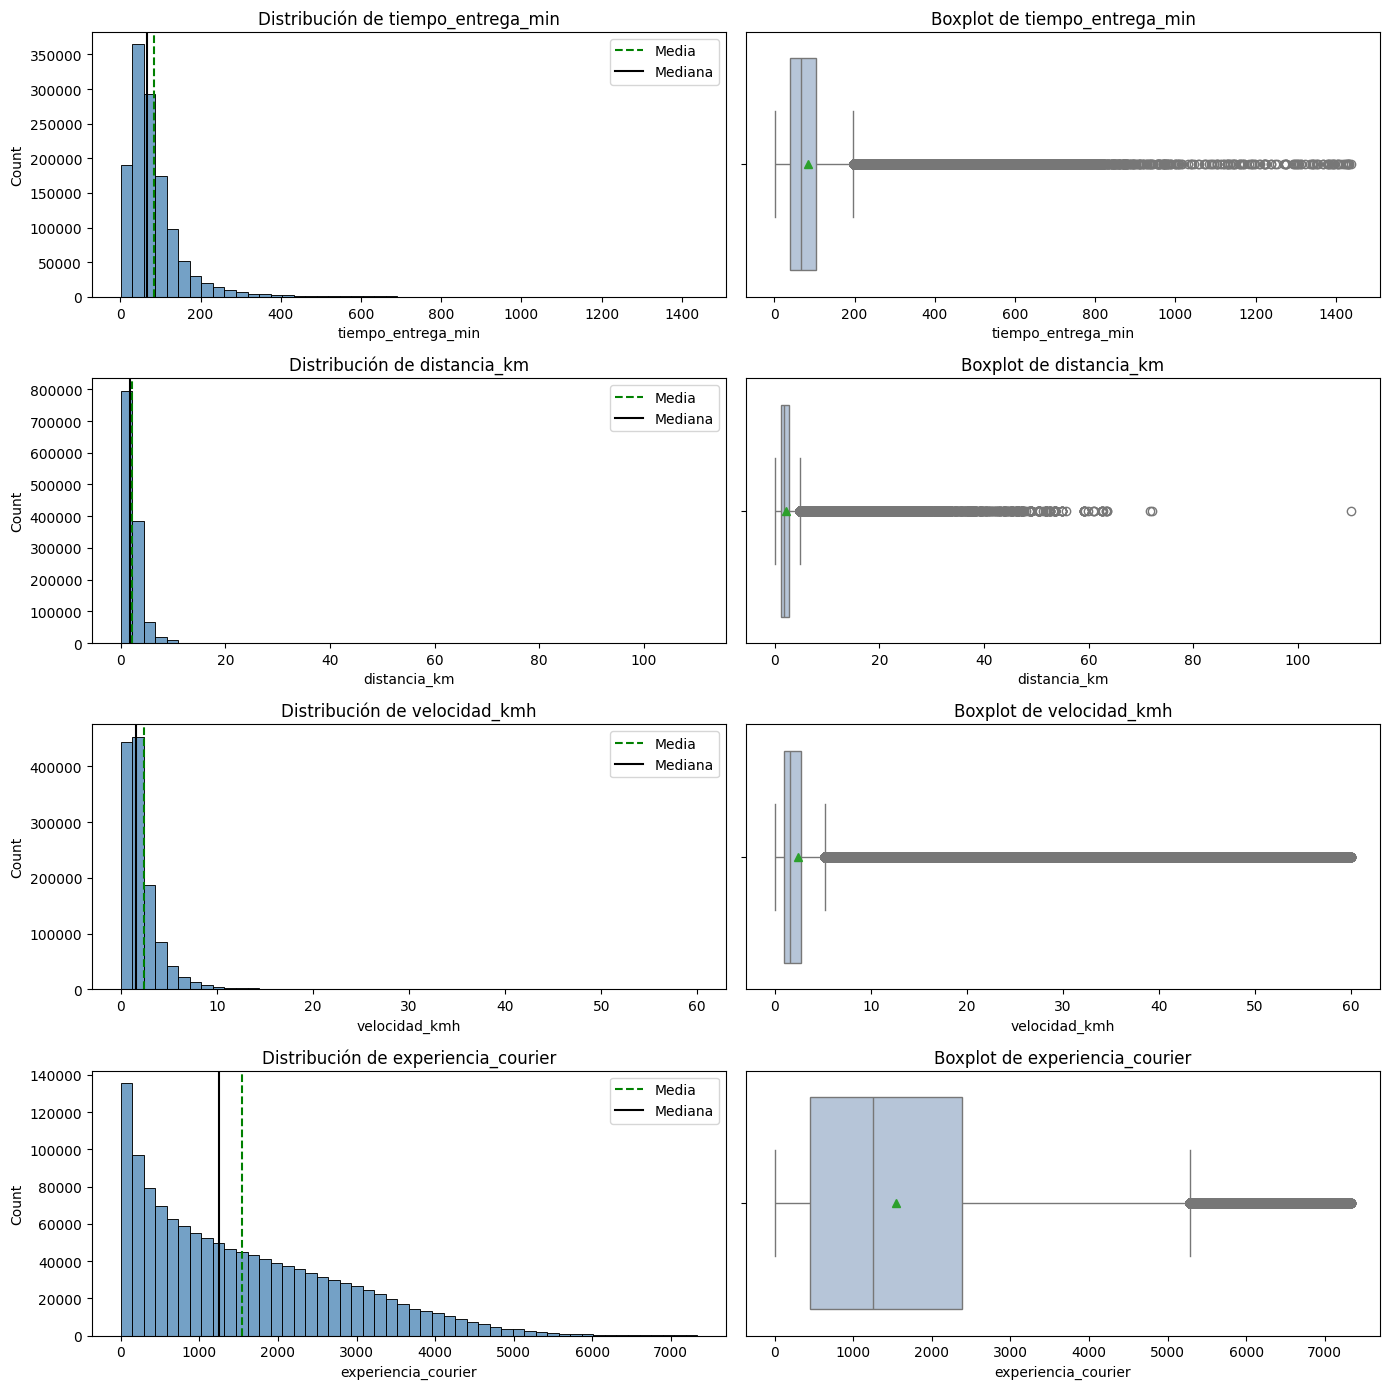

In [21]:
# Variables numéricas: histograma (con media y mediana) + boxplot lado a lado
num_cols = ['tiempo_entrega_min', 'distancia_km', 'velocidad_kmh', 'experiencia_courier']

fig, axes = plt.subplots(len(num_cols), 2, figsize=(14, 3.5 * len(num_cols)))

for i, col in enumerate(num_cols):
    # Histograma con líneas de media y mediana
    sns.histplot(data=df_limpio, x=col, bins=50, ax=axes[i, 0], color="steelblue")
    axes[i, 0].axvline(df_limpio[col].mean(), color="green", linestyle="--", label="Media")
    axes[i, 0].axvline(df_limpio[col].median(), color="black", linestyle="-", label="Mediana")
    axes[i, 0].set_title(f"Distribución de {col}")
    axes[i, 0].legend()

    # Boxplot (el triángulo marca la media)
    sns.boxplot(data=df_limpio, x=col, ax=axes[i, 1], color="lightsteelblue", showmeans=True)
    axes[i, 1].set_title(f"Boxplot de {col}")

plt.tight_layout()
plt.show()

In [22]:
# Resumen estadístico y asimetría de las variables numéricas (skewness > 1 indica fuerte asimetría a la derecha)
resumen_num = df_limpio[num_cols].describe().T
resumen_num['skewness'] = df_limpio[num_cols].skew()
resumen_num.round(2)

,count,mean,std,min,25%,50%,75%,max,skewness
tiempo_entrega_min,1277452.0,84.87,76.59,1.0,40.00,66.00,103.00,1438.00,3.45
distancia_km,1277452.0,2.22,1.87,0.0,1.20,1.82,2.68,110.19,6.89
velocidad_kmh,1277452.0,2.41,3.48,0.0,0.99,1.60,2.69,59.99,8.27
experiencia_courier,1277452.0,1546.16,1276.15,0.0,455.00,1256.00,2386.00,7335.00,0.85


##### **Observaciones:**
<small><font color="gray">Variables numéricas</font></small>

- **tiempo_entrega_min (target):** después de la limpieza, la mediana del tiempo de entrega es 66 minutos y el 50% de los pedidos se entrega entre 40 y 103 minutos. La distribución tiene asimetría a la derecha (skewness 3,45), con una cola larga de entregas lentas: el 7,7% de los pedidos demora más de 3 horas.
- **distancia_km:** la mediana de la distancia es 1,8 km y el 50% de los pedidos está entre 1,2 y 2,7 km, lo que es coherente con entregas de última milla. Tiene una fuerte asimetría a la derecha (skewness 6,89), con algunos valores extremos de hasta 110 km.
- **velocidad_kmh:** la mediana de la velocidad implícita es de solo 1,6 km/h, y el 25,7% de los pedidos está por debajo de 1 km/h. Esto muestra que el tiempo de entrega no es solo tiempo de viaje: el courier lleva varios paquetes a la vez y los reparte a lo largo de una ruta, así que cada pedido incluye el tiempo dedicado a otras entregas.
- **experiencia_courier:** va de 0 a 7.335 pedidos previos, con una mediana de 1.256. Es la variable menos asimétrica (skewness 0,85), con muchas observaciones de couriers con poca experiencia.

#### **Variables categóricas**

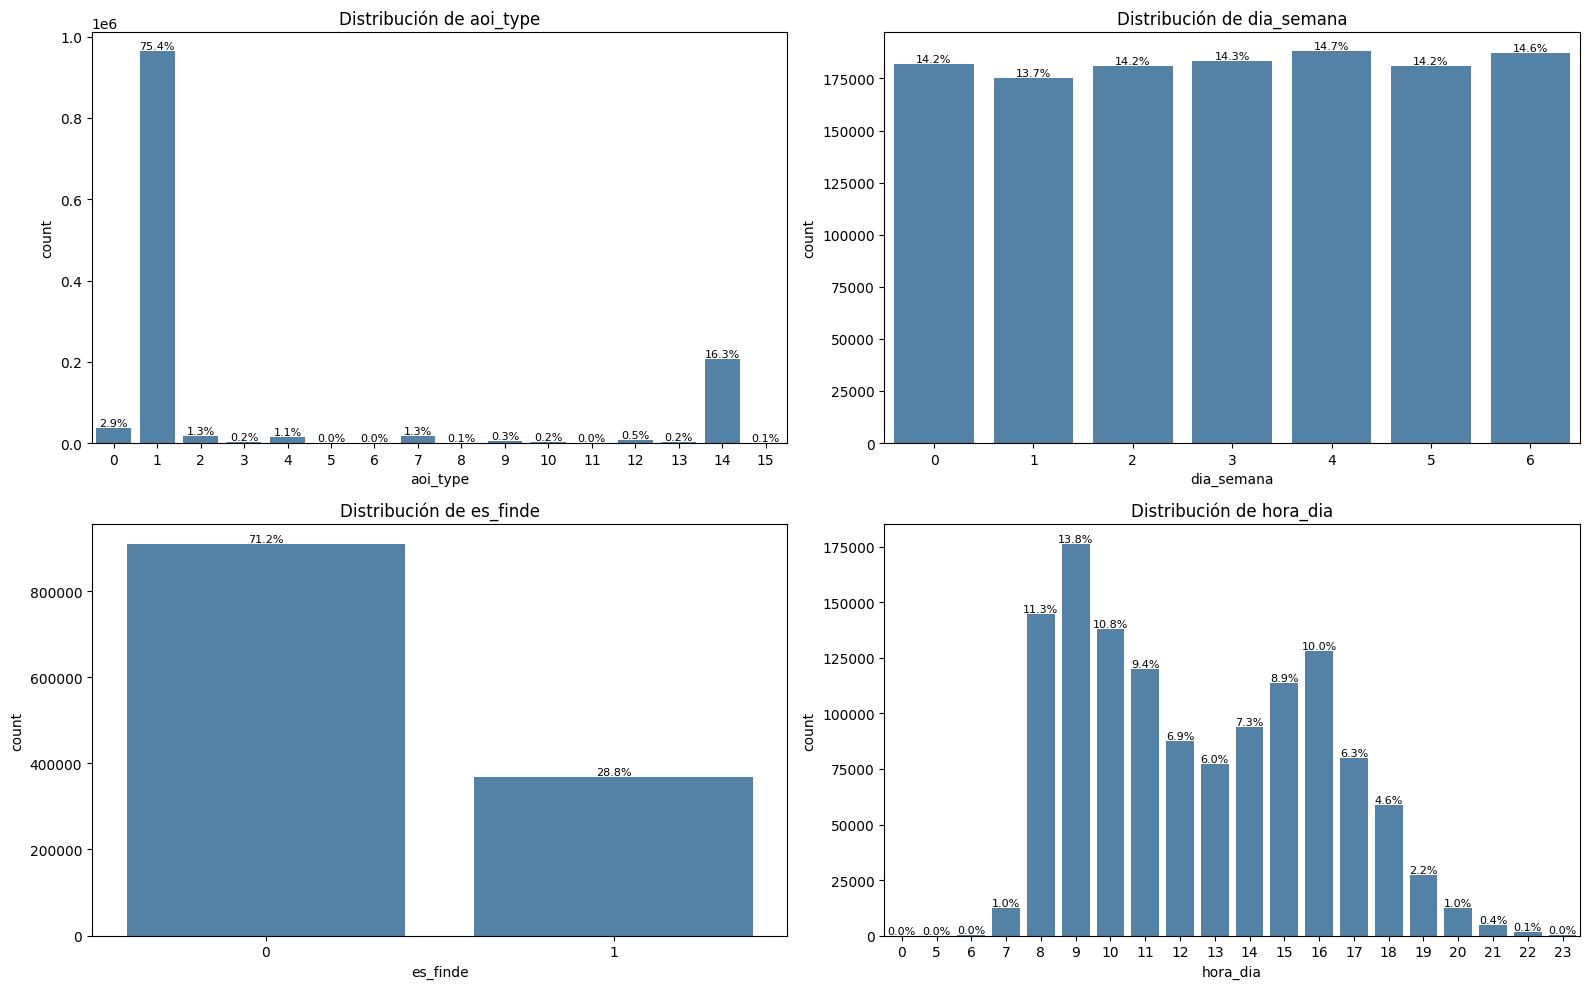

In [23]:
# Variables categóricas y discretas: gráficos de conteo con porcentajes
cat_cols = ['aoi_type', 'dia_semana', 'es_finde', 'hora_dia']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, col in zip(axes.flatten(), cat_cols):
    sns.countplot(data=df_limpio, x=col, ax=ax, color="steelblue")
    ax.set_title(f"Distribución de {col}")

    # Anotamos cada barra con su porcentaje de pedidos
    for p in ax.patches:
        pct = 100 * p.get_height() / len(df_limpio)
        ax.annotate(f"{pct:.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()

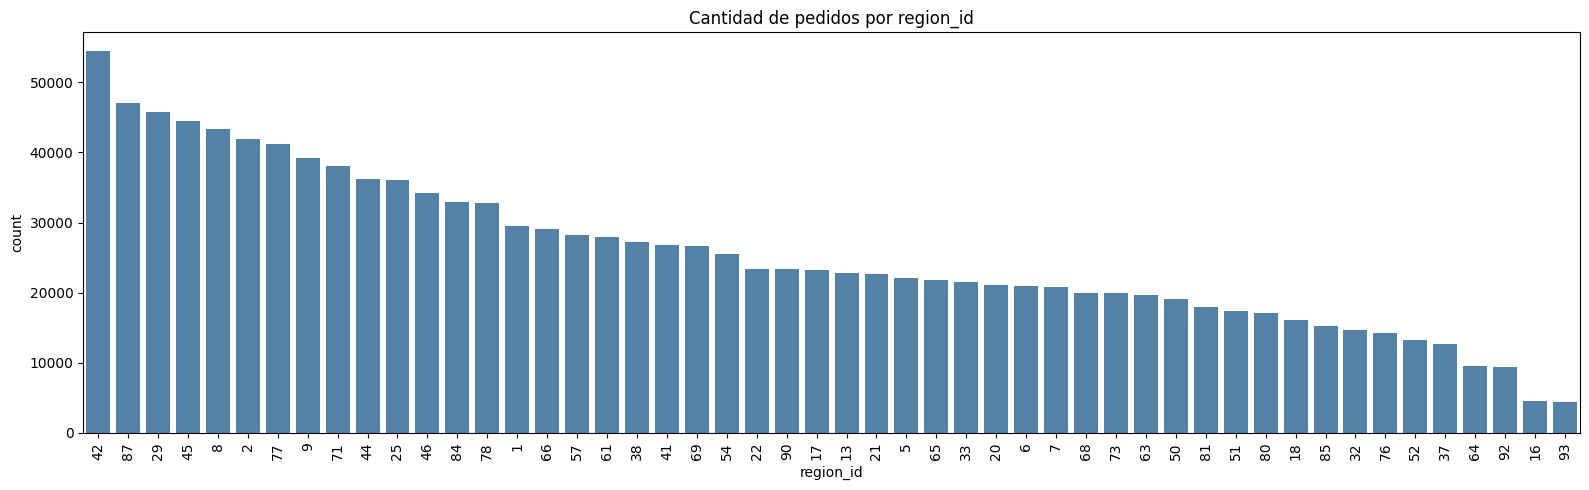

Las 10 regiones principales concentran el 33.8% de los pedidos


In [24]:
# region_id tiene demasiados valores para la grilla anterior: gráfico de conteo ordenado por cantidad de pedidos
plt.figure(figsize=(16, 5))
order = df_limpio['region_id'].value_counts().index
sns.countplot(data=df_limpio, x='region_id', order=order, color="steelblue")
plt.title("Cantidad de pedidos por region_id")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# Porcentaje de pedidos de las 10 regiones principales
top10 = df_limpio['region_id'].value_counts(normalize=True).head(10).sum() * 100
print(f"Las 10 regiones principales concentran el {top10:.1f}% de los pedidos")

##### **Observaciones:**
<small><font color="gray">Variables categóricas</font></small>

- **aoi_type:** está muy desbalanceada. El tipo 1 concentra el 75,4% de los pedidos y el tipo 14 otro 16,3%. Los otros 14 tipos tienen menos del 3% cada uno.
- **dia_semana / es_finde:** los pedidos se distribuyen de forma pareja durante la semana (alrededor del 14% por día), así que los fines de semana representan el 28,8% de los pedidos (2 de 7 días). La operación funciona todos los días con un volumen similar.
- **hora_dia:** casi todos los pedidos se aceptan entre las 7 y las 21 hs. Hay dos picos: a la mañana (9 hs, 13,8%) y a la tarde (16 hs, 10,0%).
- **region_id:** después de la limpieza quedan 50 regiones (2 de las 52 regiones originales fueron eliminadas por completo por los filtros). El volumen varía mucho entre regiones, de unos 4.300 a 54.400 pedidos, y las 10 regiones principales concentran el 33,8% de los pedidos.

### Análisis bivariado

#### **Correlación entre variables numéricas**

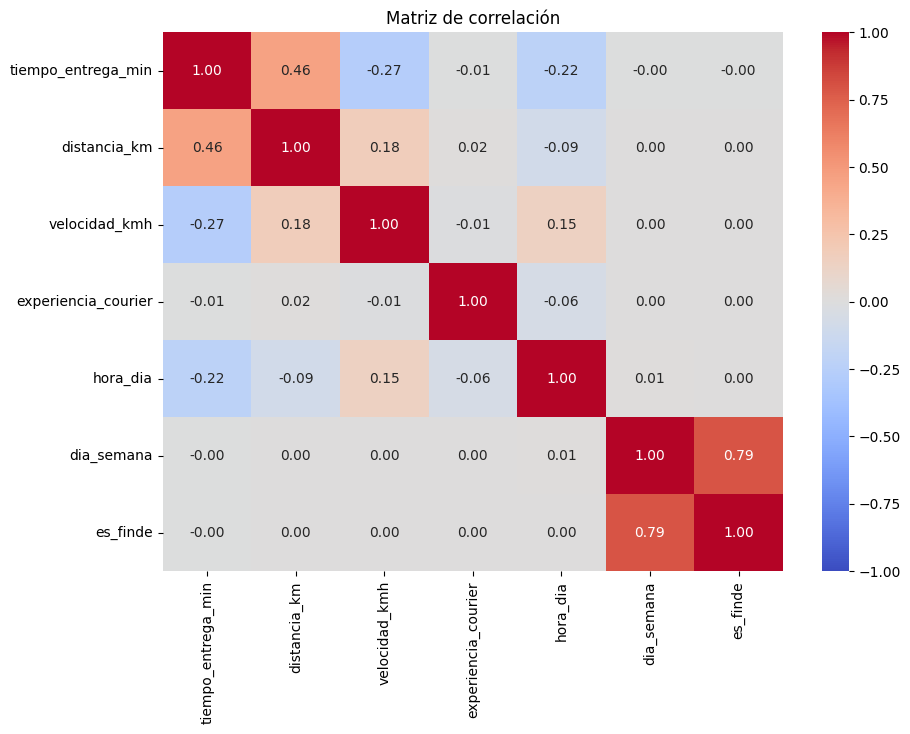

In [25]:
# Heatmap de correlación de las variables numéricas y temporales
corr_cols = num_cols + ['hora_dia', 'dia_semana', 'es_finde']

plt.figure(figsize=(10, 7))
sns.heatmap(df_limpio[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.show()

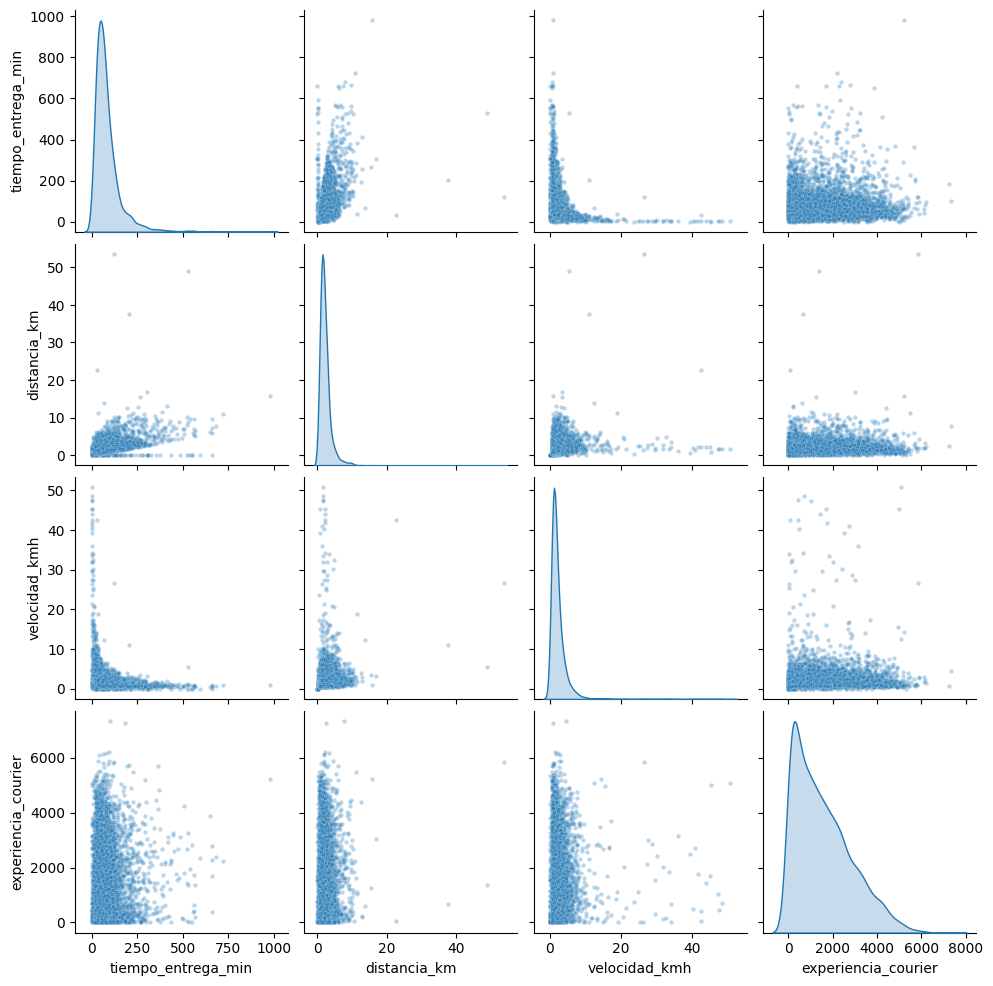

In [26]:
# Pairplot de las variables numéricas
# Usamos una muestra aleatoria de 5.000 pedidos, porque graficar 1,2 millones de puntos es demasiado lento
muestra = df_limpio[num_cols].sample(5000, random_state=42)

sns.pairplot(data=muestra, diag_kind="kde", plot_kws={"alpha": 0.3, "s": 10})
plt.show()

##### **Observaciones:**
<small><font color="gray">Correlación entre variables numéricas</font></small>

- `distancia_km` tiene la correlación más fuerte con el tiempo de entrega (0,46): a mayor distancia, mayor tiempo de entrega.
- `hora_dia` tiene una correlación negativa con el tiempo de entrega (-0,22): los pedidos aceptados más tarde en el día se entregan más rápido.
- `velocidad_kmh` está correlacionada con el tiempo de entrega (-0,27), pero se calcula con el target, así que no la usamos en el modelo.
- `experiencia_courier`, `dia_semana` y `es_finde` prácticamente no tienen correlación lineal con el tiempo de entrega (cercana a 0).
- `es_finde` está muy correlacionada con `dia_semana` (0,79), ya que se deriva de ella.
- El pairplot muestra que las relaciones son débiles y muy dispersas. Incluso la relación entre distancia y tiempo de entrega tiene mucho ruido. Esto anticipa que a un modelo lineal le va a costar explicar el tiempo de entrega.

#### **Tiempo de entrega por variable categórica**

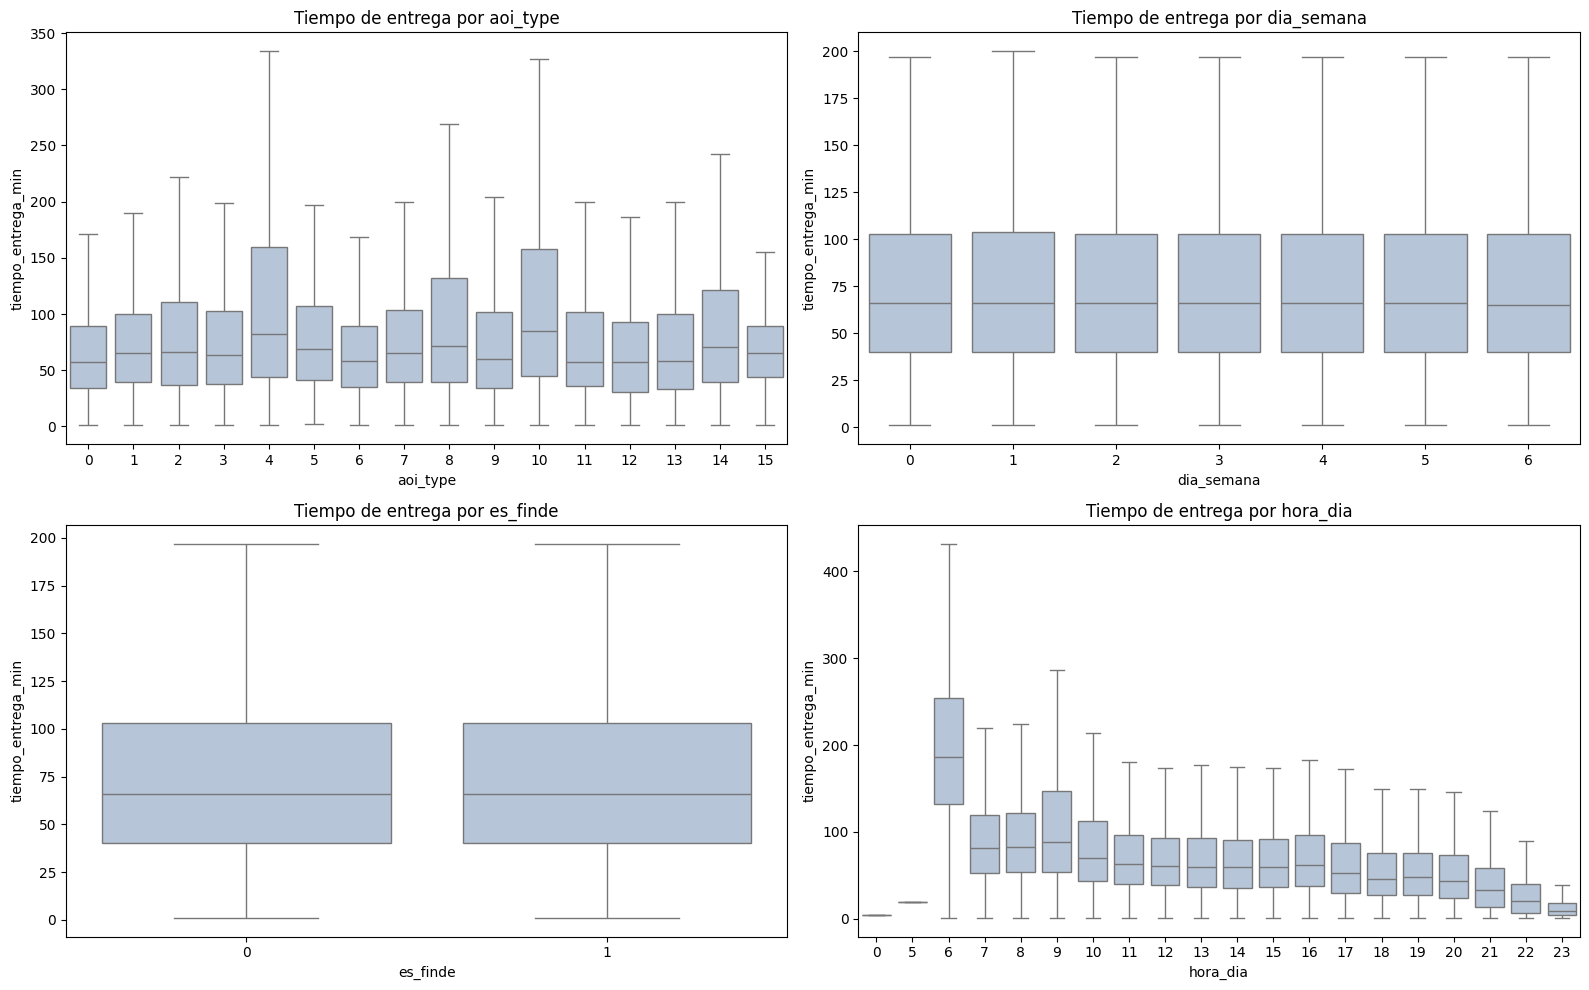

In [27]:
# Tiempo de entrega por variable categórica (outliers ocultos para que las cajas se lean mejor)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for ax, col in zip(axes.flatten(), cat_cols):
    sns.boxplot(data=df_limpio, x=col, y='tiempo_entrega_min', ax=ax, color="lightsteelblue", showfliers=False)
    ax.set_title(f"Tiempo de entrega por {col}")

plt.tight_layout()
plt.show()

In [28]:
# Mediana del tiempo de entrega por categoría
for col in cat_cols:
    print(f"\nMediana del tiempo de entrega (minutos) por {col}:")
    print(df_limpio.groupby(col)['tiempo_entrega_min'].median().round(1).to_string())


Mediana del tiempo de entrega (minutos) por aoi_type:
aoi_type
0     57.0
1     65.0
2     66.0
3     64.0
4     82.0
5     69.0
6     58.0
7     65.0
8     72.0
9     60.0
10    85.0
11    57.0
12    57.0
13    58.0
14    71.0
15    65.0

Mediana del tiempo de entrega (minutos) por dia_semana:
dia_semana
0    66.0
1    66.0
2    66.0
3    66.0
4    66.0
5    66.0
6    65.0

Mediana del tiempo de entrega (minutos) por es_finde:
es_finde
0    66.0
1    66.0

Mediana del tiempo de entrega (minutos) por hora_dia:
hora_dia
0       4.0
5      19.0
6     186.0
7      82.0
8      83.0
9      88.0
10     70.0
11     63.0
12     61.0
13     60.0
14     59.0
15     60.0
16     62.0
17     53.0
18     46.0
19     48.0
20     44.0
21     33.0
22     20.0
23      8.5


##### **Observaciones:**
<small><font color="gray">Tiempo de entrega por variable categórica</font></small>

- **hora_dia:** es la variable categórica con el efecto más claro. Los pedidos aceptados entre las 8 y las 9 hs tienen una mediana de 83–88 minutos, mientras que los aceptados después de las 18 hs tienen una mediana menor a 50 minutos (20 minutos a las 22 hs). Esto es coherente con que los couriers reciben muchos pedidos al inicio del turno y los van entregando a lo largo del día.
- **aoi_type:** las medianas van de 57 a 85 minutos. Los tipos 4 y 10 son los más lentos y los de mayor dispersión. El tipo 14 (16% de los pedidos) es más lento que el tipo 1 (mediana de 71 vs. 65 minutos).
- **dia_semana / es_finde:** los boxplots son idénticos y la mediana es de 65–66 minutos todos los días. El día de la semana no afecta el tiempo de entrega.
- En resumen, las variables con más potencial para explicar el tiempo de entrega son `distancia_km`, `hora_dia` y `aoi_type`. El día de la semana no aporta información.

## **Preprocesamiento de datos**

Antes de construir el modelo:
- Seleccionamos las features (variables independientes) y el target (variable dependiente).
- Dividimos los datos en train y test, para evaluar el modelo con datos que no vio durante el entrenamiento.
- Codificamos las features categóricas con One-Hot Encoding.

#### **Selección de features**

In [29]:
# Columnas excluidas de las features, y por qué
columnas_a_excluir = [
    'order_id',            # identificador único - sin valor predictivo
    'courier_id',          # alta cardinalidad (1.733 valores) - no generaliza; su información útil ya está en experiencia_courier
    'aoi_id',              # cardinalidad muy alta (15.564 valores) - inviable para one-hot y no generaliza
    'ds',                  # redundante - fecha en formato MMDD, ya capturada en hora_dia / dia_semana / es_finde
    'accept_time',         # timestamp crudo, no utilizable como número; ya capturado en hora_dia / dia_semana / es_finde
    'delivery_time',       # data leakage - hora real de entrega, usada para calcular el target
    'velocidad_kmh',       # data leakage - calculada con el target
    'tiempo_entrega_min',  # target (y), no puede ser feature (X)
    'lat',                 # multicolinealidad - coordenada cruda de entrega, redundante con distancia_km
    'lng',                 # multicolinealidad - igual que lat
    'accept_gps_lat',      # multicolinealidad - coordenada cruda de aceptación, redundante con distancia_km
    'accept_gps_lng',      # multicolinealidad - igual que accept_gps_lat
    'delivery_gps_lat',    # multicolinealidad - coordenada cruda de entrega, redundante con distancia_km
    'delivery_gps_lng',    # multicolinealidad - igual que delivery_gps_lat
]

target_col = 'tiempo_entrega_min'
feature_cols = [c for c in df_limpio.columns if c not in columnas_a_excluir]

print("Features finales:", feature_cols)

Features finales: ['region_id', 'aoi_type', 'distancia_km', 'experiencia_courier', 'hora_dia', 'dia_semana', 'es_finde']


In [30]:
# Separamos las features en categóricas y numéricas
columnas_categoricas = ['region_id', 'aoi_type']
columnas_numericas = ['distancia_km', 'experiencia_courier', 'hora_dia', 'dia_semana', 'es_finde']

##### **Observaciones:**
<small><font color="gray">Selección de features</font></small>

- Conservamos 7 features: 2 categóricas (`region_id`, `aoi_type`) y 5 numéricas (`distancia_km`, `experiencia_courier`, `hora_dia`, `dia_semana`, `es_finde`).
- Excluimos los identificadores con demasiados valores (`order_id`, `courier_id`, `aoi_id`), las fechas y coordenadas crudas (su información ya está capturada en las variables creadas) y las variables que generarían data leakage (`delivery_time`, `velocidad_kmh`).
- `region_id` y `aoi_type` son códigos numéricos, pero representan categorías, así que las tratamos como categóricas.
- `hora_dia`, `dia_semana` y `es_finde` se mantienen como variables numéricas.

#### **División train / test**

In [31]:
# Dividimos los datos en train (80%) y test (20%)
X = df_limpio[columnas_categoricas + columnas_numericas]
y = df_limpio[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1021961, 7) Test: (255491, 7)


##### **Observaciones:**
<small><font color="gray">División train / test</font></small>

- Usamos el 80% de los datos para entrenamiento (1.021.961 pedidos) y el 20% para test (255.491 pedidos).
- Fijamos `random_state=42` para que la división sea reproducible.
- **Limitación:** la división es aleatoria, pero los datos son temporales y los pedidos vienen en grupos (un courier acepta varios pedidos a la vez y los entrega en la misma ruta). Pedidos del mismo courier, día y ruta pueden quedar tanto en train como en test, así que las métricas de test pueden ser algo optimistas. Una división temporal (por ejemplo, entrenar con mayo–septiembre y testear con octubre) reflejaría mejor cómo se usaría el modelo para predecir pedidos futuros.

#### **One-Hot Encoding**

In [32]:
# One-Hot Encoding de las variables categóricas
# drop='first' elimina la primera categoría de cada variable para evitar la trampa de las variables dummy
# min_frequency agrupa las categorías con menos del 0,5% de los pedidos en una única categoría 'infrequent'
# dtype=np.uint8 guarda las dummies como enteros 0/1, lo que usa 8 veces menos memoria que float64
# El encoder se ajusta SOLO con train, para evitar data leakage
encoder = OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.005,
                        sparse_output=False, drop='first', dtype=np.uint8)
encoder.fit(X_train[columnas_categoricas])

X_train_ohe = encoder.transform(X_train[columnas_categoricas])
X_test_ohe = encoder.transform(X_test[columnas_categoricas])

nombres_ohe = encoder.get_feature_names_out(columnas_categoricas)

X_train_ohe_df = pd.DataFrame(X_train_ohe, columns=nombres_ohe, index=X_train.index)
X_test_ohe_df = pd.DataFrame(X_test_ohe, columns=nombres_ohe, index=X_test.index)

In [33]:
# Datasets finales: variables numéricas + dummies
X_train_final = pd.concat([X_train[columnas_numericas], X_train_ohe_df], axis=1)
X_test_final = pd.concat([X_test[columnas_numericas], X_test_ohe_df], axis=1)

print(X_train_final.shape, X_test_final.shape)
X_train_final.head()

(1021961, 60) (255491, 60)


,distancia_km,experiencia_courier,hora_dia,dia_semana,es_finde,region_id_2,region_id_5,region_id_6,region_id_7,region_id_8,...,region_id_90,region_id_92,region_id_infrequent_sklearn,aoi_type_1,aoi_type_2,aoi_type_4,aoi_type_7,aoi_type_12,aoi_type_14,aoi_type_infrequent_sklearn
1409435,2.939014,2180,19,1,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
869736,7.964760,1899,15,3,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
445023,1.120435,447,10,2,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
1040997,2.365556,2343,13,1,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
252234,4.631233,352,9,3,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0


In [34]:
# Control de los datasets finales
# No debería haber valores faltantes después del encoding
print(f"Valores faltantes en train: {X_train_final.isnull().sum().sum()}")
print(f"Valores faltantes en test: {X_test_final.isnull().sum().sum()}")

# Train y test deben tener exactamente las mismas columnas, en el mismo orden
print(f"Mismas columnas en train y test: {list(X_train_final.columns) == list(X_test_final.columns)}")

Valores faltantes en train: 0
Valores faltantes en test: 0
Mismas columnas en train y test: True


##### **Observaciones:**
<small><font color="gray">One-Hot Encoding</font></small>

- El encoder se ajusta solo con los datos de train y después se aplica a train y test, así que no se usa información del set de test durante el entrenamiento.
- Eliminamos la primera categoría de cada variable (`drop='first'`) para evitar la trampa de las variables dummy, que generaría multicolinealidad perfecta en la regresión lineal. Las categorías de referencia son la región 1 y el tipo de AOI 0.
- Las categorías con menos del 0,5% de los pedidos se agrupan en una única categoría `infrequent`, porque con tan pocas observaciones sus coeficientes serían inestables:
    - `aoi_type`: se agrupan 9 tipos poco frecuentes (1,1% de los pedidos), así que genera 6 dummies más `aoi_type_infrequent_sklearn`.
    - `region_id`: se agrupan las regiones 16 y 93, así que genera 48 dummies.
- Las dummies se guardan como `uint8` (0/1), lo que reduce la memoria del set de train de unos 560 MB a unos 100 MB.
- Los datasets finales tienen 60 columnas: 5 variables numéricas + 55 dummies.
- No hay valores faltantes, y train y test tienen las mismas columnas en el mismo orden.

## **Construcción de modelos**

Probamos **3 modelos de regresión** para predecir el tiempo de entrega (`tiempo_entrega_min`) y comparamos sus métricas:

| # | Modelo | Tipo | Por qué lo probamos |
| :--- | :--- | :--- | :--- |
| 1 | **Linear Regression** | Modelo lineal | Línea base: simple e interpretable |
| 2 | **Gradient Boosting** | Ensamble de árboles (boosting) | Cada árbol corrige los errores de los anteriores |
| 3 | **Random Forest** | Ensamble de árboles (bagging) | Captura relaciones no lineales e interacciones entre variables |

**Proceso para cada modelo:**
1. **Para los 3 modelos:**
    - **Validación cruzada (K-Fold, 5 folds)** sobre una muestra de 15.000 pedidos de train, para revisar la estabilidad del modelo.
    - **Entrenamiento final** con el set de train completo y **evaluación** en test.
    - **Ajuste de hiperparámetros** con `RandomizedSearchCV` sobre la misma muestra, y evaluación del modelo ajustado en test (solo Gradient Boosting y Random Forest, porque la regresión lineal no tiene hiperparámetros).
    - En la regresión lineal, además, revisamos la multicolinealidad (VIF) antes de entrenar y analizamos los residuos.
2. **Comparación de modelos** en el set de test.

**Métricas:**
- **RMSE** (Root Mean Squared Error): error promedio en minutos, que penaliza más los errores grandes.
- **MAE** (Mean Absolute Error): error absoluto promedio en minutos. Es la más fácil de interpretar.
- **R² y R² ajustado:** proporción de la variabilidad del tiempo de entrega que explica el modelo.
- **MAPE** (Mean Absolute Percentage Error): error promedio como porcentaje del valor real. Funciona mejor cuando no hay valores cercanos a 0, que no es nuestro caso (hay entregas de pocos minutos).

In [35]:
# Función para calcular el R² ajustado
def adj_r2_score(predictors, targets, predictions):
    r2 = r2_score(targets, predictions)
    n = predictors.shape[0]
    k = predictors.shape[1]
    return 1 - ((1 - r2) * (n - 1) / (n - k - 1))


# Función para calcular el MAPE
def mape_score(targets, predictions):
    return np.mean(np.abs(targets - predictions) / targets) * 100


# Función para calcular distintas métricas de desempeño de un modelo de regresión
def model_performance_regression(model, predictors, target):
    """
    Función para calcular distintas métricas de desempeño de un modelo de regresión

    model: regresor
    predictors: variables independientes
    target: variable dependiente
    """

    pred = model.predict(predictors)                  # Predicción con las variables independientes
    r2 = r2_score(target, pred)                       # Cálculo del R²
    adjr2 = adj_r2_score(predictors, target, pred)    # Cálculo del R² ajustado
    rmse = np.sqrt(mean_squared_error(target, pred))  # Cálculo del RMSE
    mae = mean_absolute_error(target, pred)           # Cálculo del MAE
    mape = mape_score(target, pred)                   # Cálculo del MAPE

    # Creamos un dataframe con las métricas
    df_perf = pd.DataFrame(
        {
            "RMSE": rmse,
            "MAE": mae,
            "R²": r2,
            "R² ajustado": adjr2,
            "MAPE": mape,
        },
        index=[0],
    )

    return df_perf

### **Modelo 1: Linear Regression**

#### **Revisión de multicolinealidad (VIF)**

La **multicolinealidad** ocurre cuando las variables independientes están muy correlacionadas entre sí, de modo que no aportan información propia. En ese caso, al modelo le resulta difícil estimar el efecto de cada variable sobre el target.

El **Variance Inflation Factor (VIF)** mide cuánto se infla la varianza de un coeficiente por la multicolinealidad. Por lo general, las features con un VIF mayor a 5 se tratan o se eliminan.

Calcular el VIF sobre el set de train completo (1 millón de pedidos) demora demasiado, así que lo calculamos sobre una muestra aleatoria de 50.000 pedidos, que da prácticamente el mismo resultado.

In [36]:
def checking_vif(train):
    vif = pd.DataFrame()
    vif["feature"] = train.columns

    # Calculamos el VIF de cada feature
    vif["VIF"] = [
        variance_inflation_factor(train.values, i) for i in range(len(train.columns))
    ]
    return vif

In [37]:
# VIF sobre una muestra de 50.000 pedidos de train (sobre el train completo tarda demasiado)
# Agregamos la constante para que el VIF se calcule correctamente, y luego la quitamos de los resultados
X_vif = sm.add_constant(X_train_final.sample(50000, random_state=42).astype(float))

vif_resultado = checking_vif(X_vif)
vif_resultado = vif_resultado[vif_resultado['feature'] != 'const'].sort_values('VIF', ascending=False)
vif_resultado.head(10)

,feature,VIF
54,aoi_type_1,7.048807
59,aoi_type_14,6.046519
25,region_id_42,2.842894
5,es_finde,2.654052
4,dia_semana,2.653518
19,region_id_29,2.464399
50,region_id_87,2.444432
11,region_id_9,2.393089
10,region_id_8,2.383067
6,region_id_2,2.382624


##### **Observaciones:**
<small><font color="gray">Revisión de multicolinealidad (VIF)</font></small>

- Solo `aoi_type_1` (7,0) y `aoi_type_14` (6,0) tienen un VIF mayor a 5. Juntas representan el 92% de los pedidos, así que son casi complementarias: cuando un pedido no es tipo 1, es muy probable que sea tipo 14. Es una consecuencia del encoding (la categoría de referencia, tipo 0, es chica), no un problema real de los datos.
- `dia_semana` y `es_finde` tienen un VIF de 2,7, que es aceptable aunque `es_finde` se derive de `dia_semana`.
- El resto de las variables tienen un VIF menor a 3, así que no hay multicolinealidad relevante y conservamos todas las features.

#### **Modelo base y validación cruzada**

In [38]:
# =========================================================================
# LinearRegression - Modelo base
# =========================================================================

# ---- Instanciar modelo base + K-Fold ----
# https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
modelo_lr_reg = LinearRegression()
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [39]:
# ---- Validación cruzada (K-Fold) dentro de train ---- Linear Regression
# Muestra reducida de 15.000 pedidos de train (la misma que se usa en Gradient Boosting y Random Forest)
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train_final, y_train, train_size=15000, random_state=42
)

cv_results_lr = cross_validate(
    modelo_lr_reg, X_train_sample, y_train_sample,
    cv=kf, scoring=['r2', 'neg_mean_absolute_error']
)

r2_cross_v_lr = cv_results_lr['test_r2'].mean()
mae_cross_v_lr = -cv_results_lr['test_neg_mean_absolute_error'].mean()

print("=== VALIDACIÓN CRUZADA - LinearRegression (sobre Train Sample) ===")
print(f"R² promedio en K-Fold: {r2_cross_v_lr:.4f}")
print(f"MAE promedio en K-Fold: {mae_cross_v_lr:.2f}")

=== VALIDACIÓN CRUZADA - LinearRegression (sobre Train Sample) ===
R² promedio en K-Fold: 0.2783
MAE promedio en K-Fold: 41.34


In [40]:
# ---- Entrenamiento definitivo + evaluación en test ---- Linear Regression
modelo_lr_reg.fit(X_train_final, y_train)
y_pred_lr = modelo_lr_reg.predict(X_test_final)

r2_lr = r2_score(y_test, y_pred_lr)
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

print("\n=== EVALUACIÓN FINAL - LinearRegression (sobre Test completo) ===")
print(f"R² en Test: {r2_lr:.4f}")
print(f"MAE en Test: {mae_lr:.2f}")
print(f"RMSE en Test: {rmse_lr:.2f}")


=== EVALUACIÓN FINAL - LinearRegression (sobre Test completo) ===
R² en Test: 0.2867
MAE en Test: 41.39
RMSE en Test: 65.09


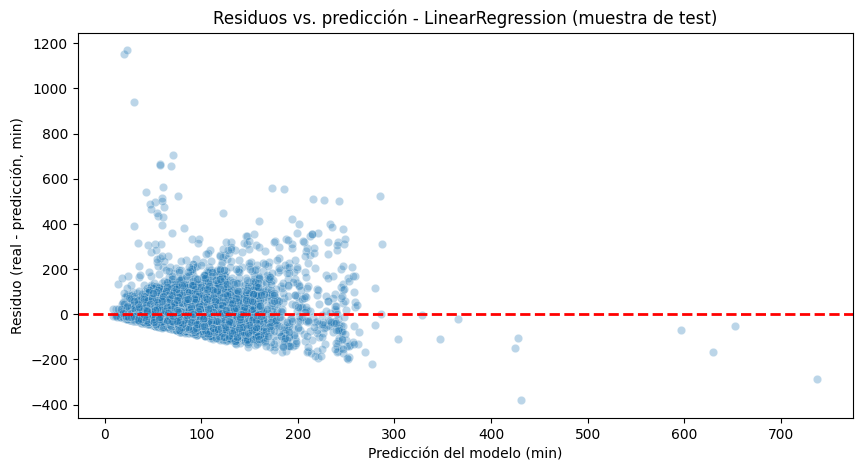

In [41]:
# ---- Análisis de residuos ---- Linear Regression
# Graficamos una muestra de 10.000 pedidos de test para que los puntos no se superpongan
residuos_lr = pd.DataFrame({'pred': y_pred_lr, 'residuo': y_test.values - y_pred_lr}).sample(10000, random_state=42)

plt.figure(figsize=(10, 5))
sns.scatterplot(data=residuos_lr, x='pred', y='residuo', alpha=0.3)
plt.axhline(0, color='red', linestyle='--', linewidth=2)
plt.title('Residuos vs. predicción - LinearRegression (muestra de test)')
plt.xlabel('Predicción del modelo (min)')
plt.ylabel('Residuo (real - predicción, min)')
plt.show()

##### **Observaciones:**
<small><font color="gray">Linear Regression – Modelo base</font></small>

- En la validación cruzada sobre la muestra de 15.000 pedidos, el R² promedio es 0,28 y el MAE 41,3 minutos.
- Entrenado con el set de train completo, el modelo alcanza un R² de 0,29, un MAE de 41,4 minutos y un RMSE de 65,1 minutos en test. Es un error alto considerando que la mediana del tiempo de entrega es 66 minutos.
- Los resultados en la muestra, en train (R² 0,28) y en test son similares, así que el modelo es estable y no hay overfitting: el problema es que el modelo es demasiado simple para los datos (underfitting).
- El gráfico de residuos muestra que los errores no se distribuyen al azar alrededor de 0: el modelo subestima las entregas largas (residuos positivos grandes) y sus predicciones se concentran en un rango estrecho. La relación entre las variables y el tiempo de entrega no es lineal, como vimos en el EDA.

#### **Ajuste de hiperparámetros**

La regresión lineal no tiene hiperparámetros que ajustar, así que no aplicamos `RandomizedSearchCV` en este modelo. Lo usamos como línea base para comparar los modelos de árboles.

### **Modelo 2: Gradient Boosting**

#### **Modelo base y validación cruzada**

In [42]:
# =========================================================================
# GradientBoostingRegressor - Modelo base
# =========================================================================

# ---- Instanciar modelo base + K-Fold ----
# https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingRegressor.html
modelo_gb_reg = GradientBoostingRegressor(random_state=42)
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [43]:
# ---- Validación cruzada (K-Fold) dentro de train ---- Gradient Boosting
# Muestra reducida de 15.000 pedidos de train (la misma que se usa en Linear Regression y Random Forest)
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train_final, y_train, train_size=15000, random_state=42
)

cv_results_gb = cross_validate(
    modelo_gb_reg, X_train_sample, y_train_sample,
    cv=kf, scoring=['r2', 'neg_mean_absolute_error']
)

r2_cross_v_gb = cv_results_gb['test_r2'].mean()
mae_cross_v_gb = -cv_results_gb['test_neg_mean_absolute_error'].mean()

print("=== VALIDACIÓN CRUZADA - GradientBoosting (sobre Train Sample) ===")
print(f"R² promedio en K-Fold: {r2_cross_v_gb:.4f}")
print(f"MAE promedio en K-Fold: {mae_cross_v_gb:.2f}")

=== VALIDACIÓN CRUZADA - GradientBoosting (sobre Train Sample) ===
R² promedio en K-Fold: 0.3860
MAE promedio en K-Fold: 38.96


In [44]:
# ---- Entrenamiento definitivo + evaluación en test ---- Gradient Boosting
modelo_gb_reg.fit(X_train_final, y_train)
y_pred_gb = modelo_gb_reg.predict(X_test_final)

r2_gb = r2_score(y_test, y_pred_gb)
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))

print("\n=== EVALUACIÓN FINAL - GradientBoosting (sobre Test completo) ===")
print(f"R² en Test: {r2_gb:.4f}")
print(f"MAE en Test: {mae_gb:.2f}")
print(f"RMSE en Test: {rmse_gb:.2f}")


=== EVALUACIÓN FINAL - GradientBoosting (sobre Test completo) ===
R² en Test: 0.4147
MAE en Test: 38.80
RMSE en Test: 58.96


##### **Observaciones:**
<small><font color="gray">Gradient Boosting – Modelo base</font></small>

- En la validación cruzada sobre la muestra de 15.000 pedidos, el R² promedio es 0,39 y el MAE 38,9 minutos.
- Entrenado con el set de train completo, el modelo alcanza un R² de 0,41 y un MAE de 38,8 minutos en test, claramente mejor que la regresión lineal.
- Los resultados en la muestra y en test son similares, así que el modelo es estable. Con los hiperparámetros por defecto (100 árboles de profundidad 3), es un modelo simple.

#### **Ajuste de hiperparámetros**

In [45]:
# ---- Búsqueda de hiperparámetros ---- Gradient Boosting
param_dist_gb = {
    "n_estimators": [200, 300, 500],
    "learning_rate": [0.01, 0.1],
    "max_depth": [1, 3, 4],
    "max_features": ["sqrt", "log2"],
}

gb_base = GradientBoostingRegressor(random_state=42)

search_gb = RandomizedSearchCV(
    gb_base,
    param_distributions=param_dist_gb,
    n_iter=20,
    cv=kf,
    scoring='neg_mean_absolute_error',  # Métrica a optimizar (MAE, la misma que en Random Forest)
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
search_gb.fit(X_train_sample, y_train_sample)

print(f"Mejor MAE en K-Fold: {-search_gb.best_score_:.2f}")

print("Mejores hiperparámetros encontrados:", search_gb.best_params_)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Mejor MAE en K-Fold: 38.76
Mejores hiperparámetros encontrados: {'n_estimators': 500, 'max_features': 'log2', 'max_depth': 4, 'learning_rate': 0.1}


In [46]:
# ---- Entrenar versión optimizada y comparar ---- Gradient Boosting
modelo_gb_reg_v2 = GradientBoostingRegressor(**search_gb.best_params_, random_state=42)
modelo_gb_reg_v2.fit(X_train_final, y_train)
y_pred_gb_v2 = modelo_gb_reg_v2.predict(X_test_final)

r2_gb_v2 = r2_score(y_test, y_pred_gb_v2)
mae_gb_v2 = mean_absolute_error(y_test, y_pred_gb_v2)

print("\n=== Comparación modelo base vs. ajustado - GradientBoosting ===")
print(f"R² base:      {r2_gb:.4f}")
print(f"R² ajustado:  {r2_gb_v2:.4f}")
print(f"MAE base:     {mae_gb:.2f}")
print(f"MAE ajustado: {mae_gb_v2:.2f}")


=== Comparación modelo base vs. ajustado - GradientBoosting ===
R² base:      0.4147
R² ajustado:  0.4365
MAE base:     38.80
MAE ajustado: 38.09


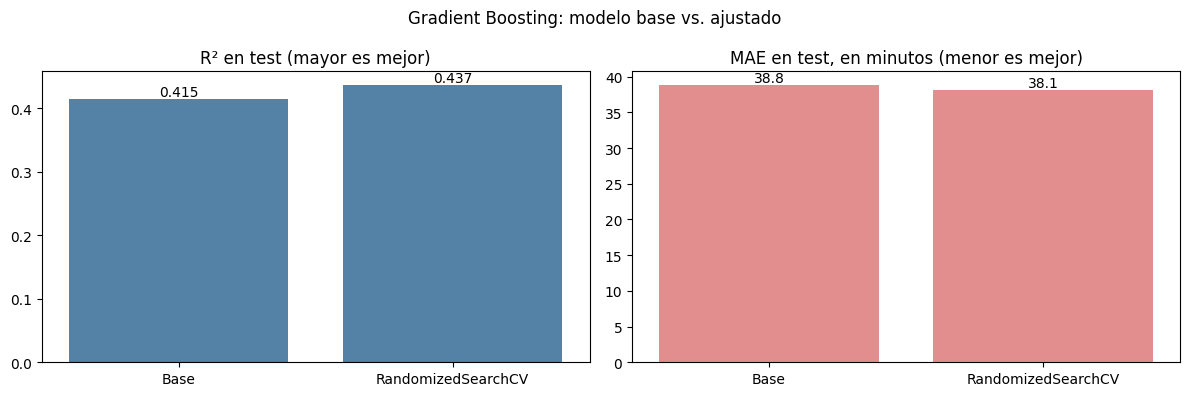

In [47]:
# ---- Comparación modelo base vs. ajustado (R² y MAE en test) ---- Gradient Boosting
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
modelos = ['Base', 'RandomizedSearchCV']

sns.barplot(x=modelos, y=[r2_gb, r2_gb_v2], ax=axes[0], color="steelblue")
axes[0].set_title("R² en test (mayor es mejor)")
axes[0].bar_label(axes[0].containers[0], fmt="%.3f")

sns.barplot(x=modelos, y=[mae_gb, mae_gb_v2], ax=axes[1], color="lightcoral")
axes[1].set_title("MAE en test, en minutos (menor es mejor)")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f")

plt.suptitle("Gradient Boosting: modelo base vs. ajustado")
plt.tight_layout()
plt.show()

##### **Observaciones:**
<small><font color="gray">Gradient Boosting – Ajuste de hiperparámetros</font></small>

- La búsqueda (optimizando el MAE) encuentra como mejores hiperparámetros `n_estimators=500`, `learning_rate=0.1`, `max_depth=4` y `max_features='log2'`, con un MAE en K-Fold de 38,8 minutos.
- Entrenado con el set de train completo, el modelo ajustado mejora levemente en test: el MAE pasa de 38,8 a 38,1 minutos y el R² de 0,415 a 0,437.
- La mejora del ajuste es chica: el límite está en la información disponible en las features, no en los hiperparámetros.

### **Modelo 3: Random Forest**

#### **Modelo base y validación cruzada**

In [48]:
# =========================================================================
# RandomForestRegressor - Modelo final
# Tener en cuanta que deben existir previamente: X_train_final, X_test_final, y_train, y_test (celda 24 del notebook)
# =========================================================================

# ---- Instanciar modelo base + K-Fold ----
# min_samples_leaf=10 y max_samples=0.3 limitan el tamaño de los árboles: sin ellos, cada árbol ocupa ~90 MB
# con 1 millón de pedidos (~9 GB para 100 árboles), más que la memoria disponible en Colab
modelo_rf_reg = RandomForestRegressor(random_state=42, n_jobs=-1, min_samples_leaf=10, max_samples=0.3)
kf = KFold(n_splits=5, shuffle=True, random_state=42) #Copiar el mismo que la celda 21 para que sean iguales

In [49]:
# ---- Validación cruzada (K-Fold) dentro de train ---- Ramdom Forest
# Usamos la misma muestra reducida que usaron para GB, para que la comparación sea justa
X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train_final, y_train, train_size=15000, random_state=42
)

cv_results_rf = cross_validate(
    modelo_rf_reg, X_train_sample, y_train_sample,
    cv=kf, scoring=['r2', 'neg_mean_absolute_error']
)

r2_cross_v_rf = cv_results_rf['test_r2'].mean()
mae_cross_v_rf = -cv_results_rf['test_neg_mean_absolute_error'].mean()

print("=== VALIDACIÓN CRUZADA - RandomForest (sobre Train Sample) ===")
print(f"R² promedio en K-Fold: {r2_cross_v_rf:.4f}")
print(f"MAE promedio en K-Fold: {mae_cross_v_rf:.2f}")

=== VALIDACIÓN CRUZADA - RandomForest (sobre Train Sample) ===
R² promedio en K-Fold: 0.3617
MAE promedio en K-Fold: 39.51


In [50]:
# ---- Entrenamiento definitivo + evaluación en test ----Ramdom Forest
modelo_rf_reg.fit(X_train_final, y_train)
y_pred_rf = modelo_rf_reg.predict(X_test_final)

r2_rf = r2_score(y_test, y_pred_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("\n=== EVALUACIÓN FINAL - RandomForest (sobre Test completo) ===")
print(f"R² en Test: {r2_rf:.4f}")
print(f"MAE en Test: {mae_rf:.2f}")
print(f"RMSE en Test: {rmse_rf:.2f}")


=== EVALUACIÓN FINAL - RandomForest (sobre Test completo) ===
R² en Test: 0.5325
MAE en Test: 34.60
RMSE en Test: 52.69


##### **Observaciones:**
<small><font color="gray">Random Forest – Modelo base</font></small>

- En la validación cruzada sobre la muestra, el R² promedio es 0,36 y el MAE 39,5 minutos, algo peor que Gradient Boosting sobre la misma muestra.
- Sin embargo, entrenado con el set de train completo, alcanza un R² de 0,53 y un MAE de 34,6 minutos en test. Es el mejor resultado hasta ahora: casi duplica el R² de la regresión lineal.
- La gran mejora entre la muestra y el set de train completo muestra que Random Forest se beneficia mucho de tener más datos.
- El R² en train (0,59) es algo mayor que en test (0,53), así que hay algo de overfitting, pero es moderado.

#### **Ajuste de hiperparámetros**

In [51]:
# ---- Búsqueda de hiperparámetros ---- Ramdom Forest
param_dist_rf = {
    "n_estimators": [200, 300, 500],
    "max_depth": [8, 12, 15, 20, None],
    "min_samples_leaf": [1, 3, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
}

rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

search_rf = RandomizedSearchCV(
    rf_base,
    param_distributions=param_dist_rf,
    n_iter=15,
    cv=kf,
    scoring='neg_mean_absolute_error',  # Métrica a optimizar (MAE, la misma que en Gradient Boosting)
    random_state=42,
    n_jobs=-1,
    verbose=1,
)
search_rf.fit(X_train_sample, y_train_sample)

print(f"Mejor MAE en K-Fold: {-search_rf.best_score_:.2f}")

print("Mejores hiperparámetros encontrados:", search_rf.best_params_) #esto me va a dar una lista, que tengo que colocar de nuevo en el código,
# volver al paso de la definicióm del modelo

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Mejor MAE en K-Fold: 38.37
Mejores hiperparámetros encontrados: {'n_estimators': 500, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 12}


In [52]:
# ---- Entrenar versión optimizada y comparar ---- Ramdom Forest
modelo_rf_reg_v2 = RandomForestRegressor(**search_rf.best_params_, random_state=42, n_jobs=-1)
modelo_rf_reg_v2.fit(X_train_final, y_train)
y_pred_rf_v2 = modelo_rf_reg_v2.predict(X_test_final)

r2_rf_v2 = r2_score(y_test, y_pred_rf_v2)
mae_rf_v2 = mean_absolute_error(y_test, y_pred_rf_v2)

print("\n=== Comparación final de modelos ===")
print(f"R² base:               {r2_gb:.4f}   (GradientBoosting)")
print(f"R² RandomForest:       {r2_rf:.4f}")
print(f"R² RandomForest (RS):  {r2_rf_v2:.4f}")
print(f"MAE base:              {mae_gb:.2f}   (GradientBoosting)")
print(f"MAE RandomForest:      {mae_rf:.2f}")
print(f"MAE RandomForest (RS): {mae_rf_v2:.2f}")


=== Comparación final de modelos ===
R² base:               0.4147   (GradientBoosting)
R² RandomForest:       0.5325
R² RandomForest (RS):  0.4725
MAE base:              38.80   (GradientBoosting)
MAE RandomForest:      34.60
MAE RandomForest (RS): 37.33


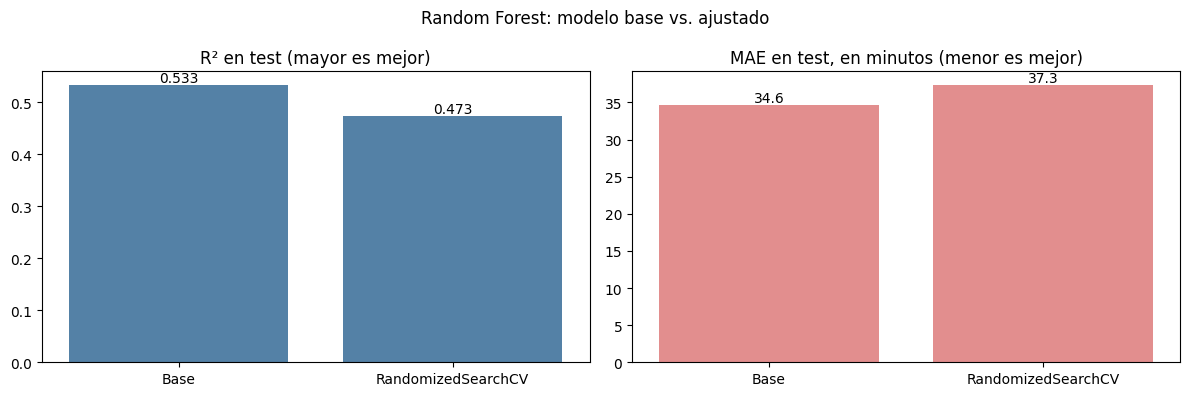

In [53]:
# ---- Comparación modelo base vs. ajustado (R² y MAE en test) ---- Random Forest
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
modelos = ['Base', 'RandomizedSearchCV']

sns.barplot(x=modelos, y=[r2_rf, r2_rf_v2], ax=axes[0], color="steelblue")
axes[0].set_title("R² en test (mayor es mejor)")
axes[0].bar_label(axes[0].containers[0], fmt="%.3f")

sns.barplot(x=modelos, y=[mae_rf, mae_rf_v2], ax=axes[1], color="lightcoral")
axes[1].set_title("MAE en test, en minutos (menor es mejor)")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f")

plt.suptitle("Random Forest: modelo base vs. ajustado")
plt.tight_layout()
plt.show()

##### **Observaciones:**
<small><font color="gray">Random Forest – Ajuste de hiperparámetros</font></small>

- Los mejores hiperparámetros encontrados son `n_estimators=500`, `max_depth=12`, `min_samples_leaf=5` y `max_features=0.5`.
- Sin embargo, el modelo ajustado tiene un peor desempeño en test que el modelo base (R² 0,47 vs. 0,53, MAE 37,3 vs. 34,6 minutos).
- La búsqueda se hizo sobre una muestra de 15.000 pedidos, donde funcionan mejor árboles menos profundos (`max_depth=12`). Con 1 millón de pedidos, árboles más profundos pueden aprender más patrones, así que los hiperparámetros elegidos en la muestra no se trasladan bien al dataset completo.

### **Comparación de modelos**

In [54]:
# Comparación de los modelos sobre el conjunto de test
comparacion = pd.concat([
    model_performance_regression(modelo_lr_reg, X_test_final, y_test),
    model_performance_regression(modelo_gb_reg, X_test_final, y_test),
    model_performance_regression(modelo_gb_reg_v2, X_test_final, y_test),
    model_performance_regression(modelo_rf_reg, X_test_final, y_test),
    model_performance_regression(modelo_rf_reg_v2, X_test_final, y_test),
])
comparacion.index = ["Linear Regression", "Gradient Boosting", "Gradient Boosting (ajustado)",
                     "Random Forest", "Random Forest (ajustado)"]
comparacion.round(3)

,RMSE,MAE,R²,R² ajustado,MAPE
Linear Regression,65.087,41.387,0.287,0.287,96.622
Gradient Boosting,58.960,38.795,0.415,0.415,95.551
Gradient Boosting (ajustado),57.850,38.093,0.437,0.436,93.844
Random Forest,52.692,34.600,0.533,0.532,83.781
Random Forest (ajustado),55.971,37.326,0.473,0.472,91.221


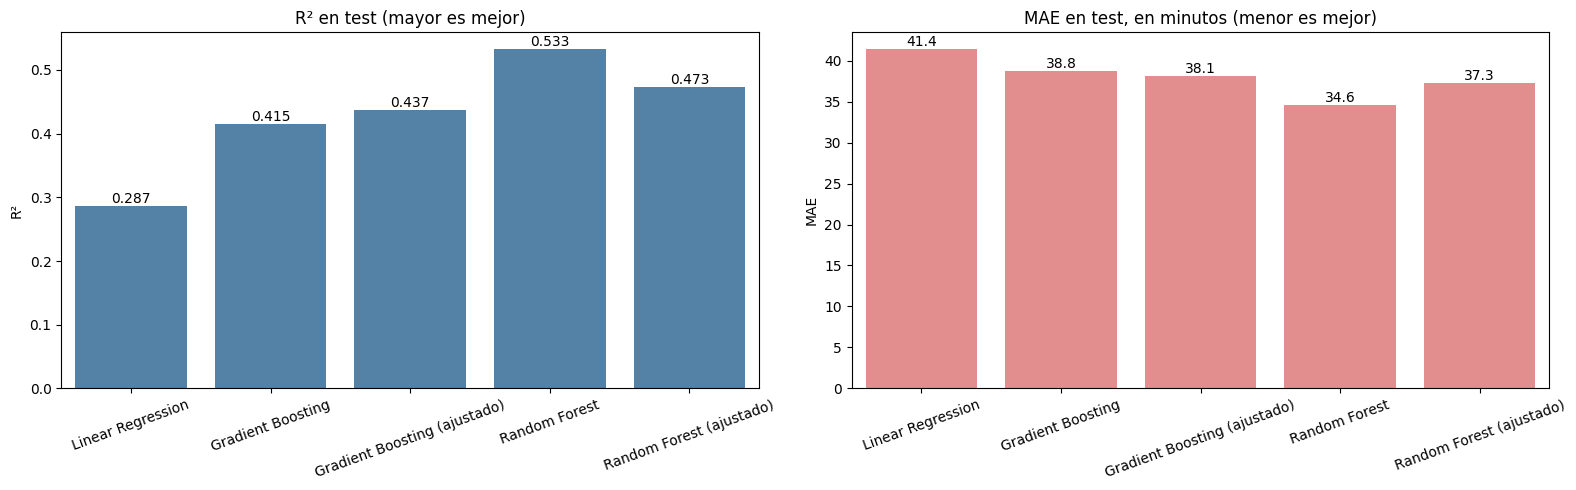

In [55]:
# R² y MAE de cada modelo sobre el conjunto de test
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.barplot(x=comparacion.index, y=comparacion["R²"], ax=axes[0], color="steelblue")
axes[0].set_title("R² en test (mayor es mejor)")
axes[0].bar_label(axes[0].containers[0], fmt="%.3f")

sns.barplot(x=comparacion.index, y=comparacion["MAE"], ax=axes[1], color="lightcoral")
axes[1].set_title("MAE en test, en minutos (menor es mejor)")
axes[1].bar_label(axes[1].containers[0], fmt="%.1f")

for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

##### **Observaciones:**
<small><font color="gray">Comparación de modelos</font></small>

- **El mejor modelo es el Random Forest base**, con un R² de 0,53 y un MAE de 34,6 minutos en test.
- Los dos modelos basados en árboles superan claramente a la regresión lineal (R² 0,29, MAE 41,4 minutos), lo que confirma que la relación entre las variables y el tiempo de entrega no es lineal.
- El ajuste de hiperparámetros sobre una muestra de 15.000 pedidos mejoró levemente a Gradient Boosting, pero empeoró a Random Forest. Con un dataset tan grande, los hiperparámetros deberían buscarse sobre una muestra más grande.
- Incluso el mejor modelo deja casi la mitad de la variabilidad sin explicar, con un error promedio de unos 35 minutos. Parte del tiempo de entrega depende de factores que no están en el dataset, como el orden en que el courier reparte los paquetes de la ruta, el tráfico o el tiempo de espera en destino.
- El MAPE es alto en todos los modelos (84–97%) por las entregas cortas, así que usamos el MAE y el R² para compararlos.